In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

### Top 10 Centralized Protocols with highest OP Balance

In [2]:
centralized_protocols_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/op_token_holding_by_different_protocols_-_centralized_protocols.csv")

centralized_protocols_data['OP Balance'] = centralized_protocols_data['OP Balance'].str.replace(r'[^\d.]', '', regex=True)

centralized_protocols_data['OP Balance'] = pd.to_numeric(centralized_protocols_data['OP Balance'], errors='coerce')

sorted_data = centralized_protocols_data.sort_values(by='OP Balance', ascending=False)

top_10_centralized_protocols = sorted_data.head(10)

print("Top 10 Centralized Protocols with the Highest OP Balance:")
print(top_10_centralized_protocols[['Protocol Name', 'OP Balance']])


Top 10 Centralized Protocols with the Highest OP Balance:
  Protocol Name    OP Balance
0   binance-cex  2.264523e+08
1           okx  4.974891e+07
2         bybit  1.071213e+07
3       gate-io  6.211278e+06
4          mexc  5.934260e+06
5        bitkub  5.566069e+06
6        bitget  4.422372e+06
7        kucoin  3.718997e+06
8           htx  2.083139e+06
9        phemex  1.603699e+05


### Top 10 Decentralized Protocols with highest OP Balance

In [3]:
decentralized_protocols_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/op_token_holding_by_different_protocols_-_decentralized_protocols.csv")

decentralized_protocols_data['OP Balance'] = decentralized_protocols_data['OP Balance'].str.replace(r'[^\d.]', '', regex=True)

decentralized_protocols_data['OP Balance'] = pd.to_numeric(decentralized_protocols_data['OP Balance'], errors='coerce')

sorted_data = decentralized_protocols_data.sort_values(by='OP Balance', ascending=False)

top_10_decentralized_protocols = sorted_data.head(10)

print("Top 10 Decentralized Protocols with the Highest OP Balance:")
print(top_10_decentralized_protocols[['Protocol Name', 'OP Balance']])


Top 10 Decentralized Protocols with the Highest OP Balance:
                    Protocol Name  OP Balance
0                         aave-v3  9873605.93
1                    velodrome-v2  4934920.02
2                      uniswap-v3  4369693.21
3                        moonwell  1164402.85
4  extra-finance-leverage-farming  1027110.27
5                     compound-v3   826609.47
6                    silo-finance   685939.58
7                       superform   491002.99
8                    lets-get-hai   375296.89
9                         exactly   364056.98


In [4]:
top_protocols = pd.concat([top_10_centralized_protocols, top_10_decentralized_protocols], ignore_index=True)

In [5]:
top_protocols

,Protocol Name,Date,OP Balance
0,binance-cex,27-12-2024,2.264523e+08
1,okx,27-12-2024,4.974891e+07
2,bybit,27-12-2024,1.071213e+07
3,gate-io,27-12-2024,6.211278e+06
4,mexc,27-12-2024,5.934260e+06
5,bitkub,27-12-2024,5.566069e+06
6,bitget,27-12-2024,4.422372e+06
7,kucoin,27-12-2024,3.718997e+06
8,htx,27-12-2024,2.083139e+06
9,phemex,27-12-2024,1.603699e+05


### Merge only top 10 protocols data

In [6]:
protocols_folder = "../data/OP Token Holding Data/"
vs_cs_file = "../../../data/votable_supply-dhruvi/data/pr_raw_data.csv"

vs_cs_data = pd.read_csv(vs_cs_file)

vs_cs_data['Date'] = pd.to_datetime(vs_cs_data['Date'], dayfirst=True)

selected_protocols = top_protocols['Protocol Name'].to_list()

final_merged_data = vs_cs_data.copy()

protocol_files = [
    file for file in os.listdir(protocols_folder) 
    if file.split('_Tokens_Data.csv')[0] in selected_protocols
]

for protocol_file in protocol_files:
    protocol_data = pd.read_csv(os.path.join(protocols_folder, protocol_file))
    
    protocol_data['Date'] = pd.to_datetime(protocol_data['Date'])
    
    protocol_name = protocol_file.split('_Tokens_Data.csv')[0]

    protocol_data.rename(columns={'OP Balance': protocol_name}, inplace=True)

    final_merged_data = pd.merge(
        final_merged_data, 
        protocol_data[['Date', protocol_name]], 
        on='Date', 
        how='left'
    )

final_merged_data.dropna(axis=1, how='all', inplace=True)

output_file = "../../../data/votable_supply-dhruvi/data/protocols_op_token_holding_data.csv"
final_merged_data.to_csv(output_file, index=False)

print(f"Merged data saved to {output_file}")


Merged data saved to ../data/Protocols_OP_Token_Holding_Data.csv


In [7]:
data = pd.read_csv("../../../data/votable_supply-dhruvi/data/protocols_op_token_holding_data.csv")

In [8]:
data.head()

,Date,Votable Supply,Circulating Supply,aave-v3,binance-cex,bitget,bybit,compound-v3,exactly,extra-finance-leverage-farming,...,htx,kucoin,lets-get-hai,mexc,moonwell,okx,silo-finance,superform,uniswap-v3,velodrome-v2
0,2022-06-05,35460574.01,214748364.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.233878e+06,NaN
1,2022-06-06,35676686.11,214748364.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.401109e+06,NaN
2,2022-06-07,35450013.62,214748364.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.961243e+06,NaN
3,2022-06-08,35248663.35,214748364.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.268457e+06,NaN
4,2022-06-09,36641371.68,214748364.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.383476e+06,NaN


In [9]:
data.isnull().sum()

Date                                0
Votable Supply                      0
Circulating Supply                  0
aave-v3                           227
binance-cex                       314
bitget                            191
bybit                             166
compound-v3                       688
exactly                           276
extra-finance-leverage-farming    335
gate-io                           177
htx                               397
kucoin                            201
lets-get-hai                      648
mexc                              367
moonwell                          829
okx                               202
silo-finance                      740
superform                         600
uniswap-v3                         44
velodrome-v2                      383
dtype: int64

### Imputte missing values with forward fill

In [10]:
# Impute missing values using forward fill (only where the previous day's data is not null)
data_imputed = data.copy() 
data_imputed.fillna(method='ffill', inplace=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14540\1147286638.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_imputed.fillna(method='ffill', inplace=True)


In [11]:
print(data_imputed.isnull().sum())

Date                                0
Votable Supply                      0
Circulating Supply                  0
aave-v3                           227
binance-cex                       313
bitget                            190
bybit                             165
compound-v3                       688
exactly                           276
extra-finance-leverage-farming    334
gate-io                           176
htx                               393
kucoin                            200
lets-get-hai                      648
mexc                              367
moonwell                          829
okx                               200
silo-finance                      740
superform                         600
uniswap-v3                          0
velodrome-v2                      383
dtype: int64


### Create a new column OP_Token_Balance 
It contains the sum of the OP Balance of all the protocols.

In [12]:
data['OP_Token_Balance'] = data.drop(['Date', 'Votable Supply', 'Circulating Supply'], axis=1).sum(axis=1)

In [ ]:
data[['Date', 'OP_Token_Balance']]

,Date,OP_Token_Balance
0,2022-06-05,4.233878e+06
1,2022-06-06,5.401109e+06
2,2022-06-07,3.961243e+06
3,2022-06-08,5.268457e+06
4,2022-06-09,6.383476e+06
...,...,...
905,2024-11-26,3.166660e+08
906,2024-11-27,3.146928e+08
907,2024-11-28,3.165531e+08
908,2024-11-29,3.187955e+08


### Find the correlation between 'Circulating Supply' and 'OP_Token_Balance'

### Pearson Correlation

In [14]:
correlation = round(data['Circulating Supply'].corr(data['OP_Token_Balance']), 2)

print(f"The correlation between 'Circulating Supply' and 'OP_Token_Balance' is: {correlation}")

The correlation between 'Circulating Supply' and 'OP_Token_Balance' is: 0.97


### Pair-Plot

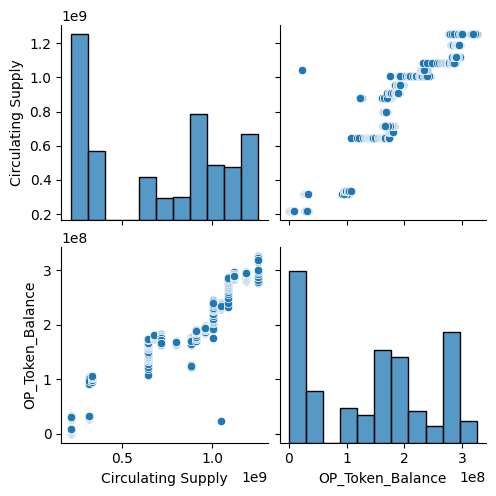

In [15]:
# Pairplot to visualize the correlation between variables
sns.pairplot(data[['Circulating Supply', 'OP_Token_Balance']])
plt.show()


### Spearman Correlation

In [16]:
# Spearman correlation
spearman_corr = data['Circulating Supply'].corr(data['OP_Token_Balance'], method='spearman')
print(f"Spearman Correlation: {spearman_corr}")


Spearman Correlation: 0.9695140208814638


In [17]:
data.to_csv("../../../data/votable_supply-dhruvi/data/protocols_op_token_holding_data.csv", index=False)

### Merge all the data

In [27]:
parameters = pd.read_csv("../../../data/votable_supply-dhruvi/data/videal_results.csv")
protocols_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/protocols_op_token_holding_data.csv")

In [28]:
parameters['Date'] = pd.to_datetime(parameters['Date'])
protocols_data['Date'] = pd.to_datetime(protocols_data['Date'])

In [30]:
protocols_data = protocols_data[['Date', 'OP_Token_Balance']]

In [31]:
merged_data = pd.merge(parameters, protocols_data, on='Date', how='inner')

In [33]:
merged_data.to_csv("../../../data/votable_supply-dhruvi/data/all_parameters.csv", index=False)